This notebook reconstructs an object as a **textured mesh starting from a sphere**, then adds **Gaussians** for what the mesh misses and fine-tunes **both together** through Gmesh.

**Ground truth.** The detailed textured Spot mesh (5856 triangles), lit by a point light, pre-rendered (color and silhouette) from 24 orbit views (training) and 6 other views (testing).

1. **Stage 1, mesh**: an icosphere (5120 triangles, sphere-mapped texture coordinates) is deformed into the object and its texture map is learned, from the color and silhouette images. The vertices are optimized in the *large steps* parameterization `u = (I + λL) v` (Nicolet et al., 2021), which smooths the updates over the surface, with light smoothness regularizers.
2. **Stage 2, hybrid**: Gaussians are added on the fitted mesh, and the mesh (vertices, texture) and the Gaussians are fine-tuned together. The mesh carries the large textured surfaces; the Gaussians the parts a deformed sphere hardly reaches (ears, horns, thin legs).
3. **Baselines**: the same number of Gaussians alone (plain 3DGS), (a) initialized on the sphere and trained for as many iterations as both stages, (b) initialized on the stage 1 mesh (the same start as the hybrid model) and trained for as many iterations as stage 2: the only difference to the hybrid model is then that the mesh is not rendered.

The helpers are shared with the script version, `examples/train_hybrid_toy.py`.

In [1]:
## Computing Device
device = 'cuda:0'
import torch
torch.cuda.set_device(device)

import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, os.path.abspath('..'))  # the repository root (this notebook runs from ./examples)
sys.path.insert(0, os.path.abspath('.'))   # ./examples, for train_hybrid_toy.py

from gmesh.scenes.mesh import Mesh
from gmesh.scenes.cameras import OrbitCamera
from train_textured_toy import load_scene, orbit_poses, make_gaussians
from train_hybrid_toy import (initial_sphere, initial_mesh_params, mesh_verts, make_mesh, make_renderers,
                              train_mesh_stage, train_hybrid_stage, train_gaussians_only, chamfer_distance)

torch.manual_seed(0)

### Ground truth and the initial sphere

ground truth: 5856 triangles; sphere: 5120 triangles


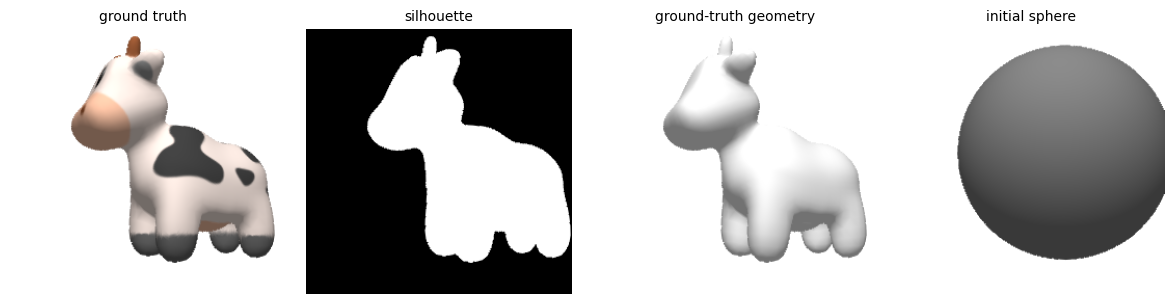

In [2]:
IMAGE_SIZE = 256
MESH_ITERS = 2000     # stage 1
HYBRID_ITERS = 2000   # stage 2
N_GAUSSIANS = 2000

gt_mesh, light = load_scene(device)            # detailed textured Spot mesh and a point light
sphere = initial_sphere(gt_mesh.verts)         # icosphere around it (dict: verts, faces, uvs, faces_uv, ...)
print(f"ground truth: {gt_mesh.num_faces} triangles; sphere: {sphere['faces'].shape[0]} triangles")

camera = OrbitCamera(image_width=IMAGE_SIZE, image_height=IMAGE_SIZE, fov_x=40, fov_y=40,
                     z_near=0.1, z_far=100, device=device)
renderers = make_renderers(camera, light)      # MeshRenderer, GaussianRasterizer, GmeshRenderer (same light)
mesh_renderer, gaussian_rasterizer, gmesh_renderer = renderers
train_poses, test_poses = orbit_poses(device)

with torch.no_grad():   # (rgb, alpha) of each view
    gt_train = [(r[0], a[0]) for r, _, a in (mesh_renderer.render(gt_mesh, p) for p in train_poses)]
    gt_test = [(r[0], a[0]) for r, _, a in (mesh_renderer.render(gt_mesh, p) for p in test_poses)]

def to_np(img):
    return img.detach().clamp(0, 1).cpu().numpy()

def show_images(images, titles, size=3.0):
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(to_np(img))
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def chamfer(verts):
    return chamfer_distance(verts.detach(), sphere['faces'], gt_mesh.verts, gt_mesh.faces)

def geometry(verts, pose, faces=None):
    """the mesh shape only: white vertex colors, lit (faces: the sphere's by default)"""
    faces = sphere['faces'] if faces is None else faces
    with torch.no_grad():
        mesh = Mesh(verts=verts.detach(), faces=faces, colors=torch.ones_like(verts))
        return mesh_renderer.render(mesh, pose)[0][0]

with torch.no_grad():
    sphere_view = mesh_renderer.render(make_mesh(sphere, initial_mesh_params(sphere, 64)), test_poses[0])[0][0]
show_images([gt_test[0][0], gt_test[0][1].expand(-1, -1, 3), geometry(gt_mesh.verts, test_poses[0], gt_mesh.faces), sphere_view],
            ['ground truth', 'silhouette', 'ground-truth geometry', 'initial sphere'])

### Stage 1: deform the sphere into a textured mesh

iter   250  loss 0.0875  test PSNR 7.94  (7.7s)
iter   500  loss 0.0289  test PSNR 24.88  (15.5s)
iter   750  loss 0.0208  test PSNR 24.88  (23.2s)
iter  1000  loss 0.0175  test PSNR 26.66  (30.9s)
iter  1250  loss 0.0153  test PSNR 28.71  (38.7s)
iter  1500  loss 0.0136  test PSNR 28.71  (46.4s)
iter  1750  loss 0.0127  test PSNR 29.50  (54.2s)
iter  2000  loss 0.0120  test PSNR 29.79  (62.1s)
Chamfer distance to the ground truth: 0.2449 (sphere) -> 0.0122


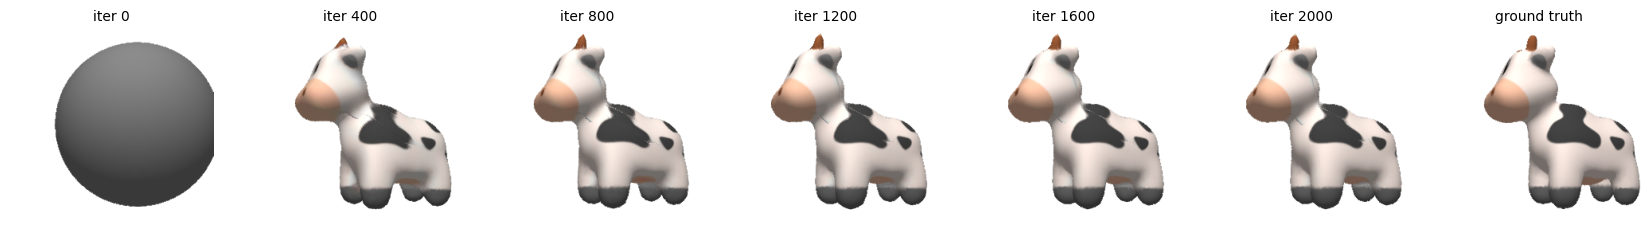

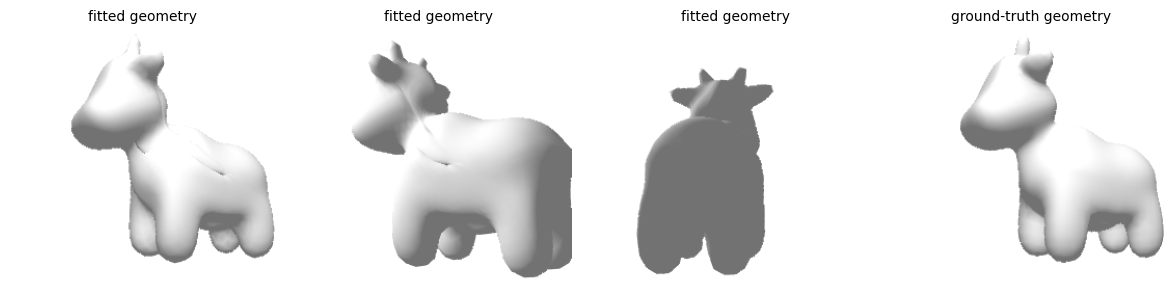

In [3]:
hist_mesh, m_params = train_mesh_stage(renderers, sphere, gt_train, gt_test, train_poses, test_poses, MESH_ITERS,
                                       tex_size=512, snapshot_every=MESH_ITERS // 5, log_every=MESH_ITERS // 8)
print(f"Chamfer distance to the ground truth: {chamfer(sphere['verts']):.4f} (sphere) -> "
      f"{chamfer(mesh_verts(sphere, m_params)):.4f}")

snaps = hist_mesh['snapshots']
show_images([views[0] for _, views in snaps] + [gt_test[0][0]], [f'iter {it}' for it, _ in snaps] + ['ground truth'],
            size=2.4)
show_images([geometry(mesh_verts(sphere, m_params), pose) for pose in test_poses[:3]] +
            [geometry(gt_mesh.verts, test_poses[0], gt_mesh.faces)], ['fitted geometry'] * 3 + ['ground-truth geometry'])

### Stage 2: add Gaussians and fine-tune the mesh and the Gaussians together

In [4]:
hist_hybrid, m_params2, g_params = train_hybrid_stage(renderers, sphere, m_params, N_GAUSSIANS, gt_train, gt_test,
                                                      train_poses, test_poses, HYBRID_ITERS,
                                                      snapshot_every=HYBRID_ITERS // 4, log_every=HYBRID_ITERS // 8)
print(f"Chamfer distance of the mesh: {chamfer(mesh_verts(sphere, m_params2)):.4f}")

iter   250  loss 0.0206  test PSNR 18.90  (9.6s)
iter   500  loss 0.0119  test PSNR 30.66  (19.3s)
iter   750  loss 0.0112  test PSNR 30.66  (28.9s)
iter  1000  loss 0.0111  test PSNR 31.09  (38.7s)
iter  1250  loss 0.0110  test PSNR 31.09  (48.3s)
iter  1500  loss 0.0106  test PSNR 31.26  (58.0s)
iter  1750  loss 0.0104  test PSNR 31.26  (67.8s)
iter  2000  loss 0.0103  test PSNR 31.33  (77.5s)
Chamfer distance of the mesh: 0.0125


### Baselines: Gaussians only

In [5]:
# (a) from the sphere, as many iterations as both stages
hist_gauss, _ = train_gaussians_only(renderers, sphere['verts'], sphere['faces'], N_GAUSSIANS, gt_train, gt_test,
                                     train_poses, test_poses, MESH_ITERS + HYBRID_ITERS,
                                     log_every=(MESH_ITERS + HYBRID_ITERS) // 8)
# (b) from the stage 1 mesh, as many iterations as stage 2
hist_gauss_mesh, _ = train_gaussians_only(renderers, mesh_verts(sphere, m_params), sphere['faces'], N_GAUSSIANS,
                                          gt_train, gt_test, train_poses, test_poses, HYBRID_ITERS,
                                          log_every=HYBRID_ITERS // 8)

iter   500  loss 0.2055  test PSNR 10.46  (3.9s)
iter  1000  loss 0.0496  test PSNR 10.46  (7.9s)
iter  1500  loss 0.0329  test PSNR 10.46  (11.9s)
iter  2000  loss 0.0281  test PSNR 10.46  (15.8s)
iter  2500  loss 0.0261  test PSNR 10.46  (19.7s)
iter  3000  loss 0.0247  test PSNR 10.46  (23.6s)
iter  3500  loss 0.0242  test PSNR 10.46  (27.5s)
iter  4000  loss 0.0233  test PSNR 27.09  (31.4s)
iter   250  loss 0.0554  test PSNR 15.83  (2.0s)
iter   500  loss 0.0221  test PSNR 15.83  (3.9s)
iter   750  loss 0.0182  test PSNR 15.83  (5.9s)
iter  1000  loss 0.0170  test PSNR 15.83  (7.8s)
iter  1250  loss 0.0160  test PSNR 15.83  (9.8s)
iter  1500  loss 0.0149  test PSNR 15.83  (11.8s)
iter  1750  loss 0.0141  test PSNR 15.83  (13.8s)
iter  2000  loss 0.0140  test PSNR 29.76  (15.8s)


### Compare on the test views

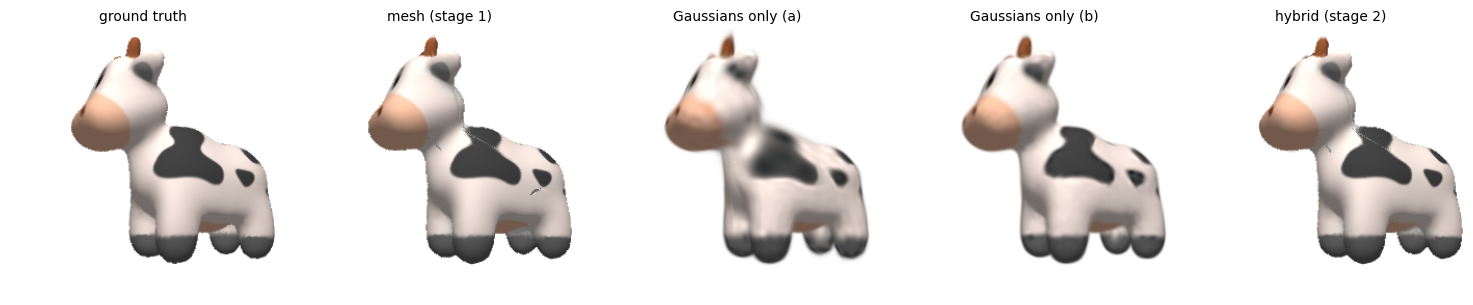

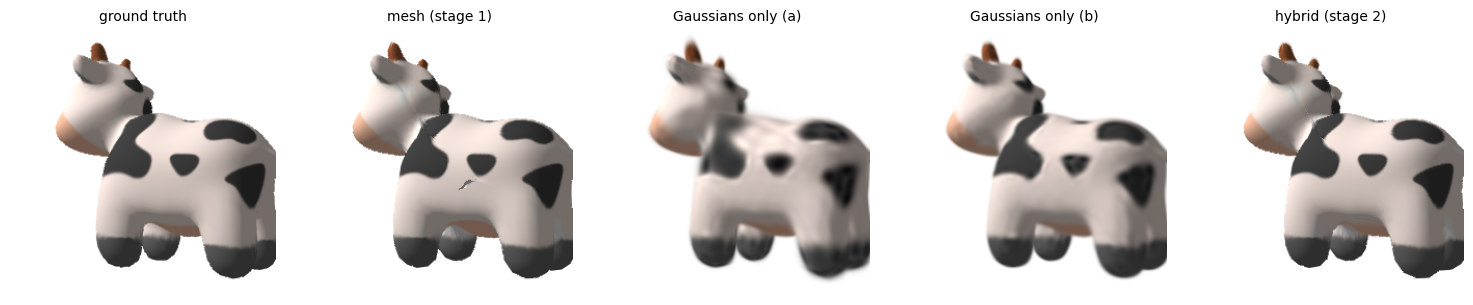

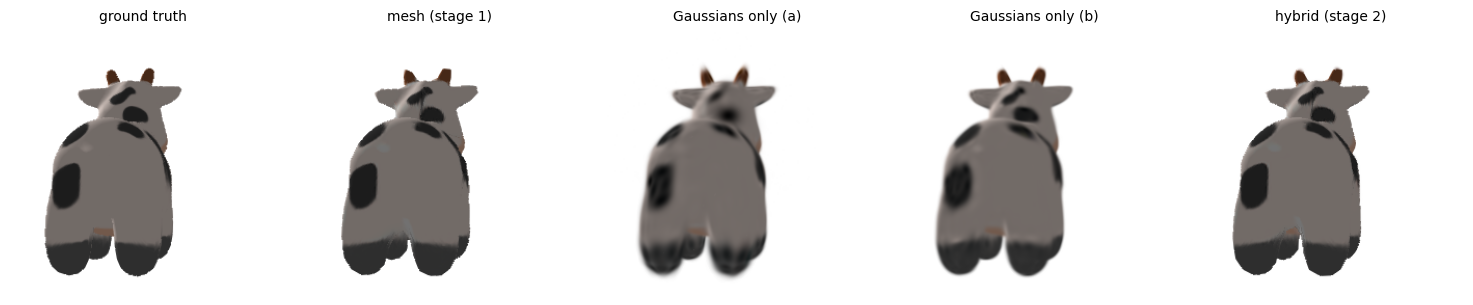

mesh (stage 1)         test PSNR  29.94 dB
Gaussians only (a)     test PSNR  27.09 dB
Gaussians only (b)     test PSNR  29.76 dB
hybrid (stage 2)       test PSNR  31.33 dB


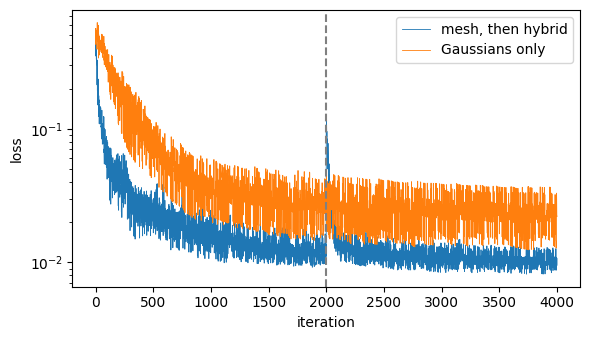

In [6]:
finals = {'mesh (stage 1)': hist_mesh, 'Gaussians only (a)': hist_gauss, 'Gaussians only (b)': hist_gauss_mesh,
          'hybrid (stage 2)': hist_hybrid}
for view in range(3):
    show_images([gt_test[view][0]] + [h['snapshots'][-1][1][view] for h in finals.values()],
                ['ground truth'] + list(finals.keys()))

for name, h in finals.items():
    print(f"{name:22s} test PSNR {h['psnr'][-1]:6.2f} dB")

plt.figure(figsize=(6, 3.5))
plt.plot(hist_mesh['loss'] + hist_hybrid['loss'], linewidth=0.6, label='mesh, then hybrid')
plt.plot(hist_gauss['loss'], linewidth=0.6, label='Gaussians only')
plt.axvline(MESH_ITERS, color='gray', linestyle='--')
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('loss'); plt.legend(); plt.tight_layout(); plt.show()

### What does each part of the hybrid model learn?

The trained hybrid model rendered as its mesh alone, its Gaussians alone (no occlusion), and both together (Gmesh).

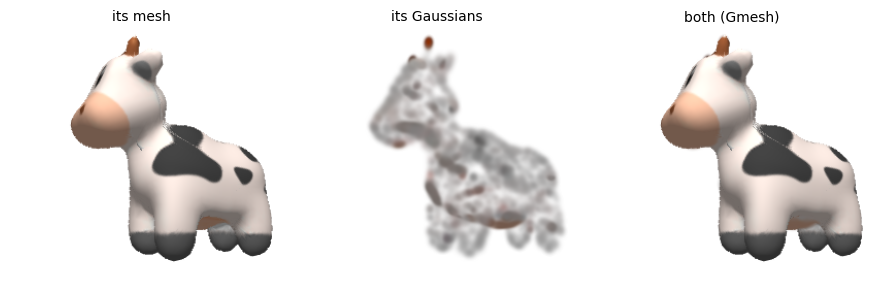

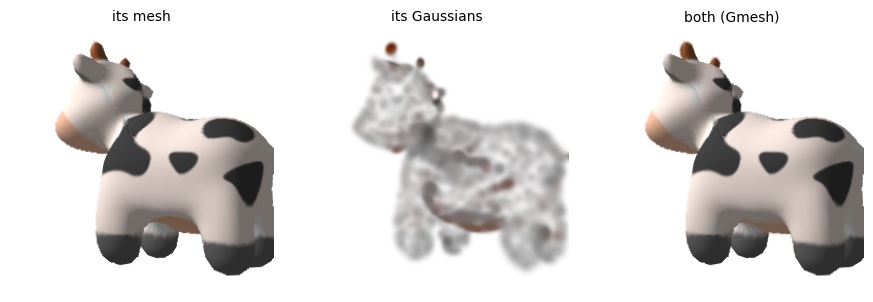

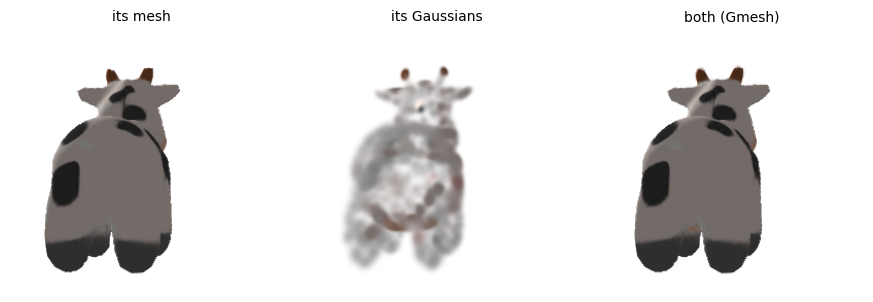

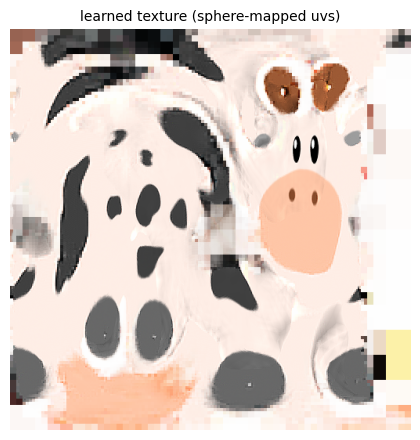

In [8]:
with torch.no_grad():
    for pose in test_poses[:3]:
        ret = gmesh_renderer.render(mesh=make_mesh(sphere, m_params2), gaussians=make_gaussians(g_params),
                                    camera_pose=pose, return_all=True)
        show_images([ret['mesh'][0][0], ret['3dgs'][0][0], ret['blend'][0][0]], ['its mesh', 'its Gaussians', 'both (Gmesh)'])
show_images([torch.sigmoid(m_params2['texture_logits'])], ['learned texture (sphere-mapped uvs)'], size=4.5)